In [175]:
# Libraries and display settings
import pandas as pd
pd.set_option("display.float_format", "{:,.0f}".format)

# Part 1 – Load and Inspect the Datasets

In [141]:
# 1) Load the three datasets into separate DataFrames
exports = pd.read_csv("Coffee_export-1.csv")
imports = pd.read_csv("Coffee_import-1.csv")
production = pd.read_csv("Coffee_production-1.csv")

In [142]:
# 2-1) Show the shape (rows, columns) of each DataFrame
print("Export shape:", exports.shape)
print("Import shape:", imports.shape)
print("Production shape:", production.shape)

# 2-2) Show the data types of each DataFrame
print("=== Export dtypes ===")
print(exports.dtypes)
print("\n=== Import dtypes ===")
print(imports.dtypes)
print("\n=== Production dtypes ===")
print(production.dtypes)

Export shape: (55, 32)
Import shape: (35, 32)
Production shape: (55, 33)
=== Export dtypes ===
Country           str
1990            int64
1991            int64
1992            int64
1993            int64
1994            int64
1995            int64
1996            int64
1997            int64
1998            int64
1999            int64
2000            int64
2001            int64
2002            int64
2003            int64
2004            int64
2005            int64
2006            int64
2007            int64
2008            int64
2009            int64
2010            int64
2011            int64
2012            int64
2013            int64
2014            int64
2015            int64
2016            int64
2017            int64
2018            int64
2019            int64
Total_export    int64
dtype: object

=== Import dtypes ===
Country           str
1990            int64
1991            int64
1992            int64
1993            int64
1994            int64
1995            int64
1996      

In [ ]:
# 3) Print the unique countries in the export and import files
export_countries = exports["Country"].unique()
import_countries = imports["Country"].unique()

print("Export countries:", len(export_countries))
print(sorted(export_countries))
print("\nImport countries:", len(import_countries))
print(sorted(import_countries))

# 4) Check whether the two country lists match(for the conbinience)
export_set = set(export_countries)
import_set = set(import_countries)

print("In both files:", len(export_set & import_set), sorted(export_set & import_set))
print("Only in export:", len(export_set - import_set))
print("Only in import:", len(import_set - export_set))

Export countries: 55
['Angola', 'Bolivia (Plurinational State of)', 'Brazil', 'Burundi', 'Cameroon', 'Central African Republic', 'Colombia', 'Congo', 'Costa Rica', 'Cuba', "Côte d'Ivoire", 'Democratic Republic of Congo', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Gabon', 'Ghana', 'Guatemala', 'Guinea', 'Guyana', 'Haiti', 'Honduras', 'India', 'Indonesia', 'Jamaica', 'Kenya', "Lao People's Democratic Republic", 'Liberia', 'Madagascar', 'Malawi', 'Mexico', 'Nepal', 'Nicaragua', 'Nigeria', 'Panama', 'Papua New Guinea', 'Paraguay', 'Peru', 'Philippines', 'Rwanda', 'Sierra Leone', 'Sri Lanka', 'Tanzania', 'Thailand', 'Timor-Leste', 'Togo', 'Trinidad & Tobago', 'Uganda', 'Venezuela', 'Viet Nam', 'Yemen', 'Zambia', 'Zimbabwe']

Import countries: 35
['   Austria', '   Belgium', '   Belgium/Luxembourg', '   Bulgaria', '   Croatia', '   Cyprus', '   Czechia', '   Denmark', '   Estonia', '   Finland', '   France', '   Germany', '   Greece', '   Hungary', '   

# Part 2 – Assess Data Quality and Structural Inconsistencies

## Part 2-1. Invesgating

In [144]:
# 1) Investigate: missing values per dataset
datasets = {"Export": exports, "Import": imports, "Production": production}

for name, df in datasets.items():
    missing = df.isnull().sum()              # NaN count per column
    print(f"=== {name}: missing values ===")
    if missing.sum() == 0:
        print("No missing values")
    else:
        print(missing[missing > 0])          # only columns that have NaN
        print("Total NaN:", missing.sum())
    print()

=== Export: missing values ===
No missing values

=== Import: missing values ===
No missing values

=== Production: missing values ===
No missing values



In [145]:
# 2) Investigate: text columns and column names with hidden spaces
for name, df in datasets.items():
    text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
    bad_names = [c for c in df.columns if c != c.strip()]
    print(f"{name} text columns: {text_cols}")
    print(f"{name} column names with extra spaces: {bad_names}")
    print()

Export text columns: ['Country']
Export column names with extra spaces: []

Import text columns: ['Country']
Import column names with extra spaces: []

Production text columns: ['Country', 'Coffee type']
Production column names with extra spaces: []



In [146]:
# 3) Investigate: country name discrepancies across files
prod_set = set(production["Country"].unique())
export_set = set(exports["Country"].unique())

print("In production but not export:", sorted(prod_set - export_set))
print("In export but not production:", sorted(export_set - prod_set))
print()

# Country names with leading/trailing spaces in each file
for name, df in datasets.items():
    spaced = [c for c in df["Country"].unique() if c != c.strip()]
    print(f"{name}: {len(spaced)} country names with extra spaces")

In production but not export: []
In export but not production: []

Export: 0 country names with extra spaces
Import: 28 country names with extra spaces
Production: 0 country names with extra spaces


## Part 2-2 Data Quality Findings
### 1. Missing values
- `.isnull().sum()` found **no missing values** in any of the three files (export, import, production).
- Export columns are `int64`. Production columns are `float64` even though there are no NaN, so the production figures include decimal values.
- **Hidden missing data:** A value of 0 can mean "no trade" or "not reported". For example, the import file has a combined `Belgium/Luxembourg` row as well as separate `Belgium` and `Luxembourg` rows, so some years are recorded as 0 in one of them. This is investigated in Part 3-3.
- **Placeholder values:** Brazil's export for 2014, 2015, and 2019 is −2,147,483,648, an impossible negative volume that represents missing data. Found while plotting in Part 5 and fixed in Part 3-3.

### 2. Numbers stored as text
- The only text columns are `Country` in all three files and `Coffee type` in production. Every year and total column is already numeric, so **no comma- or space-formatted numbers** were found.
- No column names have leading or trailing spaces.
- I still apply `pd.to_numeric()` to the numeric columns in Part 3 as a safety step, so the pipeline also works on a messier version of the data.
- Production uses crop-year headers (`1990/91` … `2019/20`), while export and import use calendar years (`1990` … `2019`). Year columns therefore can't be matched by name across files without renaming.

### 3. Country name discrepancies
- **Leading whitespace:** 28 of the 35 import countries start with three spaces (e.g. `'   Austria'`). Export and production have none. Without stripping, `'   Austria'` and `'Austria'` would be treated as different countries.
- **Production vs. export:** The two files contain exactly the same 55 country names, so no renaming is needed between them.
- **Export vs. import:** 0 countries appear in both files. Export lists producing countries and import lists consuming countries, so an inner merge on `Country` would return an empty table. The trade balance in Part 4 needs an outer merge.
- **Official UN names:** Names use formal UN style (`Viet Nam`, `Bolivia (Plurinational State of)`, `United States of America`). They already match across these files but would need mapping if combined with outside data.

# Part 3 – Clean the Datasets

# Part 3–1 Column cleanup

In [147]:
# Save the original names so we can show before/after
before = {"Export": exports.columns.tolist(),
          "Import": imports.columns.tolist(),
          "Production": production.columns.tolist()}

# 1) Strip spaces from every column name (safety step, even though none were found)
for df in [exports, imports, production]:
    df.columns = df.columns.str.strip()

# 2) Production crop years '1990/91' -> calendar year '1990'
production.columns = [col[:4] if "/" in col else col for col in production.columns]

# 3) Rename text and total columns to one lowercase style
rename_map = {
    "Country": "country",
    "Coffee type": "coffee_type",
    "Total_export": "total_export",
    "Total_import": "total_import",
    "Total_production": "total_production",
}
exports = exports.rename(columns=rename_map)
imports = imports.rename(columns=rename_map)
production = production.rename(columns=rename_map)

In [148]:
# Check: show the first 3 and last 2 column names, before and after
after = {"Export": exports.columns.tolist(),
         "Import": imports.columns.tolist(),
         "Production": production.columns.tolist()}

for name in after:
    print(f"=== {name} ===")
    print("Before:", before[name][:3], "...", before[name][-2:])
    print("After: ", after[name][:3], "...", after[name][-2:])
    print()

# All three files now share the same year columns?
year_cols = [c for c in exports.columns if c.isdigit()]
print("Same years in all files:",
      all(c in imports.columns and c in production.columns for c in year_cols))

=== Export ===
Before: ['Country', '1990', '1991'] ... ['2019', 'Total_export']
After:  ['country', '1990', '1991'] ... ['2019', 'total_export']

=== Import ===
Before: ['Country', '1990', '1991'] ... ['2019', 'Total_import']
After:  ['country', '1990', '1991'] ... ['2019', 'total_import']

=== Production ===
Before: ['Country', 'Coffee type', '1990/91'] ... ['2019/20', 'Total_production']
After:  ['country', 'coffee_type', '1990'] ... ['2019', 'total_production']

Same years in all files: True


- **Stripped whitespace** from all column names as a safety step (none was found in Part 2).
- **Unified naming style:** renamed `Country`, `Coffee type`, and the three `Total_*` columns to lowercase snake_case (`country`, `coffee_type`, `total_export`, ...). One consistent style makes later code easier to read and avoids case-sensitive `KeyError`s.
- **Aligned year columns:** production used crop years (`1990/91`), while export and import used calendar years (`1990`). I kept the first four characters so all three files share the same year labels (`1990` … `2019`). Trade-off: a crop year runs from one autumn to the next summer, so this is a simplification, but it makes year-by-year comparison across files possible.

# Part 3-2 Convert number columns stored as text into real numbers

In [149]:
# 1) Find the number columns without typing 30 names
def get_number_cols(df):
    # year columns are all digits ('1990'); total columns start with 'total'
    return [c for c in df.columns if c.isdigit() or c.startswith("total")]

# 2) Cleaning steps: text -> remove commas and spaces -> number
def to_number(series):
    text = series.astype(str)                        # treat every value as text
    text = text.str.replace(",", "", regex=False)    # '1,234'  -> '1234'
    text = text.str.strip()                          # ' 1234 ' -> '1234'
    return pd.to_numeric(text, errors="coerce")      # '1234' -> 1234, unreadable -> NaN

print("Export number columns:", len(get_number_cols(exports)))
print("Import number columns:", len(get_number_cols(imports)))
print("Production number columns:", len(get_number_cols(production)))

Export number columns: 31
Import number columns: 31
Production number columns: 31


In [150]:
# Demo on one column: show the type before and after conversion
as_text = exports["1990"].astype(str)
print("Before:", as_text.dtype, as_text.head(3).tolist())

as_number = to_number(as_text)
print("After: ", as_number.dtype, as_number.head(3).tolist())

Before: str ['5040000', '9360000', '1016160000']
After:  int64 [5040000, 9360000, 1016160000]


In [151]:
# Apply the conversion to every number column in all three files
frames = {"Export": exports, "Import": imports, "Production": production}

for name, df in frames.items():
    for col in get_number_cols(df):
        df[col] = to_number(df[col])

# Check: every number column is numeric, and no new NaN was created
for name, df in frames.items():
    cols = get_number_cols(df)
    all_numeric = all(pd.api.types.is_numeric_dtype(df[c]) for c in cols)
    print(f"{name}: all numeric = {all_numeric}, "
          f"dtypes = {df[cols].dtypes.unique().tolist()}, "
          f"NaN = {df[cols].isnull().sum().sum()}")

Export: all numeric = True, dtypes = [dtype('int64')], NaN = 0
Import: all numeric = True, dtypes = [dtype('int64')], NaN = 0
Production: all numeric = True, dtypes = [dtype('float64')], NaN = 0


- **Finding the columns:** instead of typing 31 names, I select columns whose name is all digits (years) or starts with `total`.
- **Conversion steps:** each column is treated as text, commas and spaces are removed, and `pd.to_numeric(errors="coerce")` converts it to a number. Any value that still can't be read becomes NaN instead of crashing the pipeline.
- **Result:** the raw files were already numeric, so the values did not change. Running the conversion anyway makes the pipeline safe for messier versions of the data (e.g. `"1,234 "`). The demo cell shows one column going from `str` to `int64`.
- **Check:** all number columns are numeric and no new NaN was created by the conversion.

# Part 3-3 Identify missing data

In [176]:
# Count NaN and zeros in each file
for name, df in frames.items():
    cols = get_number_cols(df)
    nan_count = df[cols].isnull().sum().sum()           # real NaN
    zero_count = (df[cols] == 0).sum().sum()            # zeros (possible hidden missing)
    all_zero_rows = df.loc[df[cols[-1]] == 0, "country"].tolist()   # total = 0
    print(f"{name}: NaN = {nan_count}, zeros = {zero_count}, "
          f"countries with total 0 = {all_zero_rows}")

Export: NaN = 0, zeros = 117, countries with total 0 = []
Import: NaN = 0, zeros = 54, countries with total 0 = []
Production: NaN = 0, zeros = 77, countries with total 0 = []


In [153]:
# Do the combined and separate rows report the same years? (risk of double-counting)
year_cols = [c for c in imports.columns if c.isdigit()]
bl = imports[imports["country"].str.strip().isin(["Belgium", "Luxembourg", "Belgium/Luxembourg"])]

for _, row in bl.iterrows():
    years = [c for c in year_cols if row[c] > 0]
    span = f"{years[0]}–{years[-1]}" if years else "no data"
    print(f"{row['country'].strip():<20} reports in: {span}")

Belgium              reports in: 1999–2019
Belgium/Luxembourg   reports in: 1990–1998
Luxembourg           reports in: 1999–2019


In [154]:
# Hidden missing values: negative volumes are impossible
for name, df in {"Export": exports, "Import": imports, "Production": production}.items():
    year_cols = [c for c in df.columns if c.isdigit()]
    neg = df[year_cols] < 0
    for idx in df.index[neg.any(axis=1)]:
        bad_years = [y for y in year_cols if neg.loc[idx, y]]
        print(f"{name}: {df.loc[idx, 'country']} -> {bad_years}, value = {df.loc[idx, bad_years[0]]:,}")

Export: Brazil -> ['2014', '2015', '2019'], value = -2,147,483,648


In [155]:
# Replace impossible negative values with NaN, then fill them from neighbouring years
for df, total in [(exports, "total_export"), (imports, "total_import"), (production, "total_production")]:
    year_cols = [c for c in df.columns if c.isdigit()]
    df[year_cols] = df[year_cols].astype(float)
    df[year_cols] = df[year_cols].mask(df[year_cols] < 0)           # negative -> NaN
    df[year_cols] = df[year_cols].interpolate(axis=1, limit_direction="both")
    df[total] = df[year_cols].sum(axis=1)                           # recompute total from clean years

print("Brazil 2013–2019 (bn kg):")
print((exports.loc[exports["country"] == "Brazil", [str(y) for y in range(2013, 2020)]] / 1e9).round(2))

Brazil 2013–2019 (bn kg):
   2013  2014  2015  2016  2017  2018  2019
2     2     2     2     2     2     2     2


In [181]:
# Handling: keep zeros as real values; fill any NaN with 0 as a safety step
for name, df in frames.items():
    cols = get_number_cols(df)
    df[cols] = df[cols].fillna(0)

# Check: no NaN left
for name, df in frames.items():
    print((exports.loc[exports["country"] == "Brazil", [str(y) for y in range(2013, 2020)]] / 1e9).round(2).to_string(float_format="{:.2f}".format))

   2013  2014  2015  2016  2017  2018  2019
2  1.90  1.95  2.00  2.06  1.86  2.14  2.14
   2013  2014  2015  2016  2017  2018  2019
2  1.90  1.95  2.00  2.06  1.86  2.14  2.14
   2013  2014  2015  2016  2017  2018  2019
2  1.90  1.95  2.00  2.06  1.86  2.14  2.14


- **Identification:** `.isnull().sum()` found no NaN in any file, including after the `to_numeric` conversion. I also counted zeros, because a 0 could be either "no trade" or "not reported".
- **Decision: keep zeros and fill any NaN with 0.** These are official trade and production records, so a 0 most likely means no recorded trade or output that year. The `fillna(0)` is a safety step for future data.
- **Why not drop rows?** Dropping would remove whole countries and their other 29 years of real data. It would also bias totals toward large producers, because small countries are the ones most likely to have zero years.
- **Why not fill with the mean or median?** That would invent coffee volumes that were never recorded and inflate the global totals. The median is safer than the mean here (a few huge countries like Brazil skew the mean), but both still create data.
- **Belgium/Luxembourg:** The combined row reports only in 1990–1998, and the separate `Belgium` and `Luxembourg` rows report only in 1999–2019. The periods don't overlap, so this is a change in reporting, not double-counting. 39 of the 54 zeros in the import file come from these three rows ("reported elsewhere", not "no trade"). Global totals are correct, but any single one of these rows on its own has an incomplete time series.

- **Hidden missing values found in the chart:** global exports appeared to halve in 2014–2015 and 2019 while imports kept rising. Tracing the drop showed **Brazil's exports recorded as exactly −2,147,483,648** in 2014, 2015, and 2019. This is the minimum 32-bit integer, a common placeholder for missing data, and a negative volume is impossible. It was the only negative value in all three files. `.isnull()` cannot detect it because the cell holds a number.
- **Handling: replaced negatives with NaN and interpolated across years.** Brazil is the largest exporter, so leaving the values would make world exports look like they halved, and filling with 0 would erase a full year of its trade. Linear interpolation uses Brazil's own neighbouring years, which keeps the trend realistic. Trade-off: the filled values are estimates, not reported figures, and 2019 (the last year) can only copy 2018. Totals were recomputed from the cleaned year columns.

# Part 3-4 Standardize country names

In [157]:
# Save totals before cleaning so we can check nothing was lost
import_total_before = imports["total_import"].sum()
import_rows_before = len(imports)

# 1) Strip leading/trailing spaces from text values in all three files
exports["country"] = exports["country"].str.strip()
imports["country"] = imports["country"].str.strip()
production["country"] = production["country"].str.strip()
production["coffee_type"] = production["coffee_type"].str.strip()

# 2) One mapping, applied to all three files
#    Belgium and Luxembourg were reported together until 1998 and separately from 1999
country_map = {
    "Belgium": "Belgium/Luxembourg",
    "Luxembourg": "Belgium/Luxembourg",
}
exports["country"] = exports["country"].replace(country_map)
imports["country"] = imports["country"].replace(country_map)
production["country"] = production["country"].replace(country_map)

# 3) Combine rows that now share the same name (adds the three Belgium/Luxembourg rows together)
imports = imports.groupby("country", as_index=False).sum()

In [158]:
# Check 1: no country names with extra spaces left
for name, df in {"Export": exports, "Import": imports, "Production": production}.items():
    spaced = [c for c in df["country"] if c != c.strip()]
    print(f"{name}: {len(spaced)} names with extra spaces")

# Check 2: Belgium/Luxembourg is now one row with no gap years
bl = imports[imports["country"] == "Belgium/Luxembourg"]
year_cols = [c for c in imports.columns if c.isdigit()]
print("\nBelgium/Luxembourg rows:", len(bl))
print("Zero years:", (bl[year_cols] == 0).sum().sum())

# Check 3: rows went from 35 to 33, but the total import volume did not change
print(f"\nImport rows: {import_rows_before} -> {len(imports)}")
print("Total import unchanged:", import_total_before == imports["total_import"].sum())

# Check 4: production and export still have exactly the same countries
print("Production = Export countries:", set(production["country"]) == set(exports["country"]))

Export: 0 names with extra spaces
Import: 0 names with extra spaces
Production: 0 names with extra spaces

Belgium/Luxembourg rows: 1
Zero years: 0

Import rows: 35 -> 33
Total import unchanged: True
Production = Export countries: True


- **Whitespace:** stripped leading/trailing spaces from `country` in all three files (28 import names had three leading spaces) and from `coffee_type`.
- **One mapping for all files:** the same `country_map` dictionary is applied to export, import, and production, so a name can never be fixed in one file and missed in another.
- **Belgium/Luxembourg:** the import file reported them as one row in 1990–1998 and as two rows from 1999. I mapped `Belgium` and `Luxembourg` to `Belgium/Luxembourg` and summed the rows with `groupby`. This gives one continuous 1990–2019 series. Import rows went from 35 to 33 and total import volume is unchanged.
- **Production vs. export:** names already matched exactly (55 countries), so no other renaming was needed. Export and import still share no countries, which is expected (producers vs. consumers) and handled with an outer merge in Part 4.

# Part 4 – Business & Trade Questions

In [159]:
# 1) largest change in production from the earliest to the latest year
first_year, last_year = "1990", "2019"

# Sum per country (safety step: one row per country already)
prod = production.groupby("country", as_index=False)[[first_year, last_year]].sum()

prod["change"] = prod[last_year] - prod[first_year]      # + increase, - decrease
prod["abs_change"] = prod["change"].abs()                # size of change, ignoring direction

top5_change = prod.nlargest(5, "abs_change")[["country", first_year, last_year, "change"]]
print(top5_change.to_string(index=False))

winner = top5_change.iloc[0]
direction = "increase" if winner["change"] > 0 else "decrease"
print(f"\nLargest change: {winner['country']} ({direction} of {winner['change']:,.0f})")

  country          1990          2019        change
   Brazil 1,637,160,000 3,492,660,000 1,855,500,000
 Viet Nam    78,600,000 1,829,220,000 1,750,620,000
 Ethiopia   174,540,000   440,580,000   266,040,000
 Honduras    94,080,000   355,860,000   261,780,000
Indonesia   446,460,000   685,980,000   239,520,000

Largest change: Brazil (increase of 1,855,500,000)


In [160]:
# 2) why an outer merge is needed
inner = pd.merge(exports[["country"]], imports[["country"]], on="country", how="inner")
print("Inner merge rows:", len(inner))   # 0 expected: no country is in both files

Inner merge rows: 0


In [161]:
# Trade balance = total exports - total imports
trade = pd.merge(
    exports[["country", "total_export"]],
    imports[["country", "total_import"]],
    on="country",
    how="outer",               # keep every country from both files
)
# A country missing from one file has no recorded trade there -> 0
trade[["total_export", "total_import"]] = trade[["total_export", "total_import"]].fillna(0)
trade["trade_balance"] = trade["total_export"] - trade["total_import"]

print("Rows after outer merge:", len(trade))   # 55 + 33 = 88 expected

Rows after outer merge: 88


In [177]:
# Top 5 net exporters and importers
top5_exporters = trade.nlargest(5, "trade_balance")[["country", "trade_balance"]]
top5_importers = trade.nsmallest(5, "trade_balance")[["country", "trade_balance"]]

print("Top 5 net exporters:")
print(top5_exporters.to_string(index=False))
print("\nTop 5 net importers:")
print(top5_importers.to_string(index=False))

Top 5 net exporters:
  country  trade_balance
   Brazil 46,343,580,000
 Viet Nam 24,924,480,000
 Colombia 19,878,480,000
Indonesia 10,607,940,000
    India  6,933,960,000

Top 5 net importers:
                 country   trade_balance
United States of America -42,507,660,000
                 Germany -31,481,400,000
                   Italy -13,272,120,000
                   Japan -12,422,760,000
                  France -11,972,520,000


### 1. Largest change in production (1990 → 2019)
**Brazil** shows the largest change: production **increased by about 1.86 billion kg**, from 1.64 billion kg in 1990 to 3.49 billion kg in 2019 (more than double). I compared absolute changes so that large decreases would count as much as large increases, but all of the top 5 are increases.

| Rank | Country | 1990 | 2019 | Change |
|---|---|---|---|---|
| 1 | Brazil | 1.64 bn | 3.49 bn | +1.86 bn |
| 2 | Viet Nam | 0.08 bn | 1.83 bn | +1.75 bn |
| 3 | Ethiopia | 0.17 bn | 0.44 bn | +0.27 bn |
| 4 | Honduras | 0.09 bn | 0.36 bn | +0.26 bn |
| 5 | Indonesia | 0.45 bn | 0.69 bn | +0.24 bn |

Viet Nam is second in absolute change, but it grew about **23 times** from a small 1990 base, the most dramatic shift in where coffee is grown. (Values appear to be in kg.)

### 2. Trade balance (total exports − total imports, 1990–2019)
Export and import files share no countries (inner merge = 0 rows), so I used an **outer merge** and filled the missing side with 0. A producer missing from the import file has no recorded imports, and a consumer missing from the export file has no recorded exports. Totals use the cleaned data, with Brazil's three placeholder years interpolated (see Part 3-3).

**Top 5 net exporters:** Brazil (46.3 bn kg), Viet Nam (24.9 bn), Colombia (19.9 bn), Indonesia (10.6 bn), India (6.9 bn)

**Top 5 net importers:** United States of America (−42.5 bn kg), Germany (−31.5 bn), Italy (−13.3 bn), Japan (−12.4 bn), France (−12.0 bn)

Because the two files cover different countries, the trade balance equals total exports for producers and negative total imports for consumers. Brazil alone exported more coffee over the period than the USA, the largest importer, bought.

In [163]:
# 3) global production share by coffee type (1990–2019)
print("Coffee types:", production["coffee_type"].unique().tolist())

type_totals = (production.groupby("coffee_type")["total_production"]
               .sum()
               .sort_values(ascending=False))

type_share = (type_totals / type_totals.sum() * 100).round(1)   # percent of world total

q3 = pd.DataFrame({"total_production": type_totals, "share_%": type_share})
print(q3)
print("\nShares add up to:", type_share.sum())

Coffee types: ['Robusta/Arabica', 'Arabica', 'Arabica/Robusta', 'Robusta']
                 total_production  share_%
coffee_type                               
Arabica/Robusta    96,668,400,000       43
Robusta/Arabica    63,480,120,000       28
Arabica            57,968,520,000       26
Robusta             7,617,780,000        3

Shares add up to: 100.00000000000001


In [164]:
# 4) countries that export coffee but have zero recorded production
exp_prod = pd.merge(
    exports[["country", "total_export"]],
    production[["country", "total_production"]],
    on="country",
    how="left",                     # keep every exporter
)
exp_prod["total_production"] = exp_prod["total_production"].fillna(0)

no_production = exp_prod[(exp_prod["total_export"] > 0) & (exp_prod["total_production"] == 0)]
print("Exporters with zero total production:", len(no_production))
print(no_production.to_string(index=False))

Exporters with zero total production: 0
Empty DataFrame
Columns: [country, total_export, total_production]
Index: []


In [165]:
# Extra check: years where a country exported but recorded 0 production that same year
year_cols = [c for c in exports.columns if c.isdigit()]
e = exports.set_index("country")[year_cols]
p = production.set_index("country")[year_cols]

mismatch = (e > 0) & (p == 0)                     # True where export > 0 and production = 0
mismatch_years = mismatch.sum(axis=1)             # number of such years per country
print(mismatch_years[mismatch_years > 0].sort_values(ascending=False))

country
Lao People's Democratic Republic    8
Yemen                               8
Gabon                               3
Equatorial Guinea                   2
Guyana                              1
dtype: int64


### 3. Global production share by coffee type (1990–2019)

| Coffee type | Total production | Share |
|---|---|---|
| Arabica/Robusta | 96.7 bn kg | 43% |
| Robusta/Arabica | 63.5 bn kg | 28% |
| Arabica | 58.0 bn kg | 26% |
| Robusta | 7.6 bn kg | 3% |

Countries whose main type is Arabica (Arabica + Arabica/Robusta) account for about **69%** of production, and Robusta-led countries (Robusta + Robusta/Arabica) for about **31%**.

**Limitation:** the production file has one row per country, so `coffee_type` labels each country's *main* type rather than splitting its beans. All of a mixed producer's output is counted under one label. These shares therefore describe production by country classification, not the exact global ratio of Arabica to Robusta beans.

### 4. Exporters with zero recorded production
**No country** exports coffee while having zero total production. The production and export files list exactly the same 55 countries, and every one of them has production on record.

**Year-level check:** although no exporter has zero *total* production, five countries exported coffee in years when their recorded production was 0:

| Country | Years with exports but 0 production |
|---|---|
| Lao People's Democratic Republic | 8 |
| Yemen | 8 |
| Gabon | 3 |
| Equatorial Guinea | 2 |
| Guyana | 1 |

Possible explanations: selling stored stock from earlier harvests, the crop-year vs. calendar-year mismatch introduced when `1990/91` was mapped to `1990` (a harvest can be exported in the following calendar year), re-exporting beans bought from neighbouring producers, or production that was simply not reported (a hidden missing value recorded as 0). The data alone cannot tell these apart, but all of these countries are small producers, where a single unreported year has a large effect.

This dataset only lists producing countries in the export file, so re-exporting consumers (for example European roasters that import, roast, and export coffee) would not show up here even though they exist in real trade.

# Part 5 – Visualizations

In [166]:
import matplotlib.pyplot as plt

BILLION = 1e9                                    # show kg values in billions
year_cols = [c for c in exports.columns if c.isdigit()]

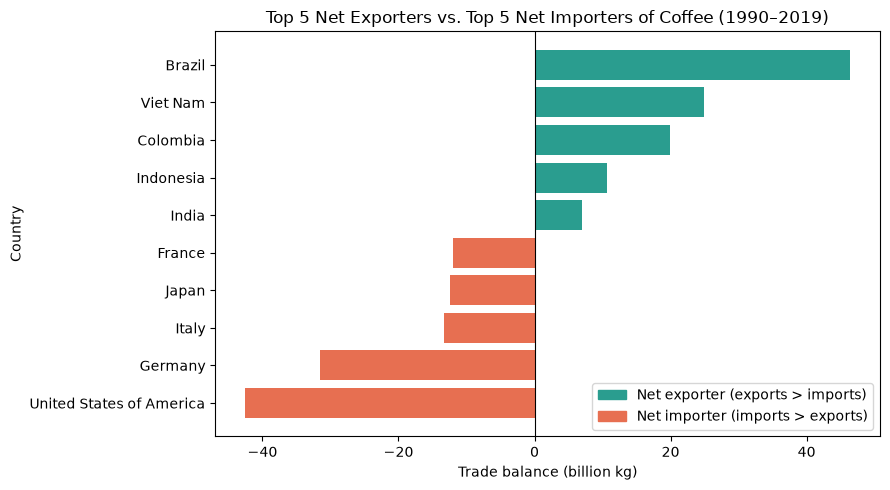

In [174]:
# Chart 1: top 5 net exporters vs top 5 net importers
chart1 = pd.concat([top5_exporters, top5_importers.iloc[::-1]])   # exporters on top, importers below
colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in chart1["trade_balance"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(chart1["country"], chart1["trade_balance"] / BILLION, color=colors)
ax.axvline(0, color="black", linewidth=0.8)      # zero line between the two groups
ax.invert_yaxis()                                # largest exporter at the top

# Legend: one entry per group
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2a9d8f", label="Net exporter (exports > imports)"),
                   Patch(color="#e76f51", label="Net importer (imports > exports)")],
          loc="lower right")

ax.set_title("Top 5 Net Exporters vs. Top 5 Net Importers of Coffee (1990–2019)")
ax.set_xlabel("Trade balance (billion kg)")
ax.set_ylabel("Country")
plt.tight_layout()
plt.show()

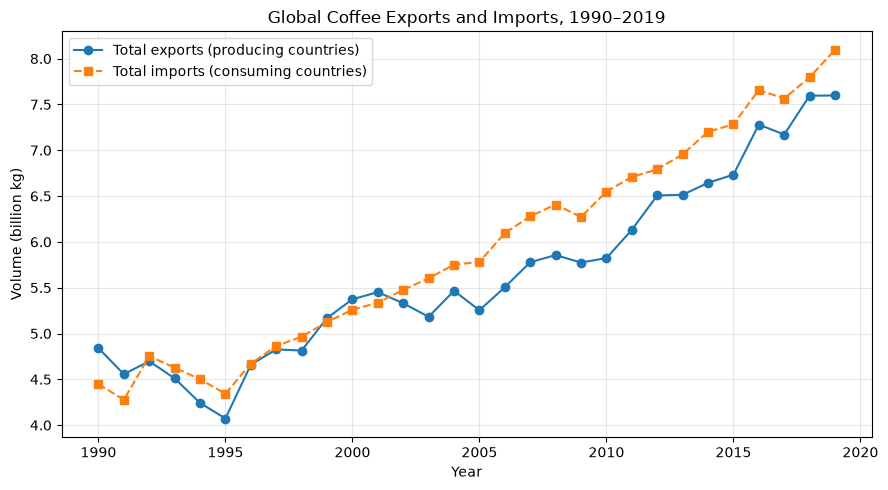

In [168]:
# Chart 2: global exports (and imports) over time
global_exports = exports[year_cols].sum() / BILLION
global_imports = imports[year_cols].sum() / BILLION
years = [int(y) for y in year_cols]              # numbers, so the x-axis is in order

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(years, global_exports, marker="o", label="Total exports (producing countries)")
ax.plot(years, global_imports, marker="s", linestyle="--", label="Total imports (consuming countries)")

ax.set_title("Global Coffee Exports and Imports, 1990–2019")
ax.set_xlabel("Year")
ax.set_ylabel("Volume (billion kg)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

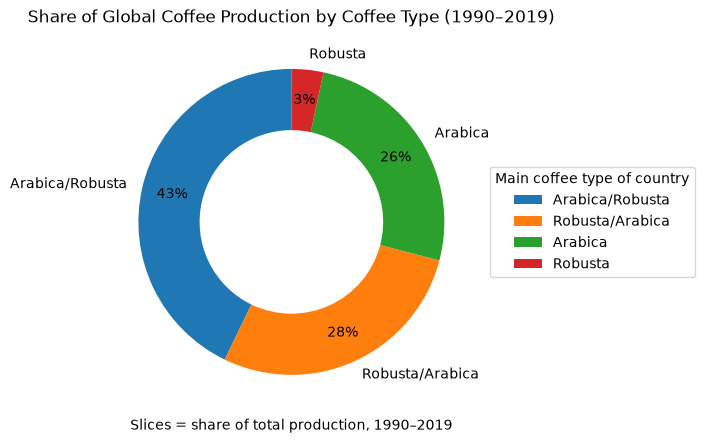

In [178]:
# Chart 3: share of global production by coffee type
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    type_totals,
    labels=type_totals.index,
    autopct="%1.0f%%",                           # show percent on each slice
    startangle=90,
    wedgeprops={"width": 0.4},                   # makes it a donut
    pctdistance=0.8
)
ax.legend(title="Main coffee type of country", loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Share of Global Coffee Production by Coffee Type (1990–2019)")
ax.set_xlabel("Slices = share of total production, 1990–2019")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

1. **Net exporters vs. net importers:** a diverging bar chart instead of a stacked bar, because export and import countries don't overlap (stacking would always put 0 on one side). Positive bars are net exporters, negative bars are net importers.
2. **Global trend:** exports and imports over 1990–2019 on one line chart, to show supply and demand growing together. The first version of this chart showed exports halving in 2014–2015 and 2019 while imports kept rising. That mismatch led to the placeholder values in Brazil's data (fixed in Part 3-3). After cleaning, the two lines follow the same upward trend.
3. **Coffee type share:** a donut chart of production by each country's main coffee type (see the Q3 limitation).

-------

## Supporting calculation for Part 6

In [171]:
# Supply concentration: share of global production from the top 3 producers (1990–2019)
prod_share = production.set_index("country")["total_production"].sort_values(ascending=False)
top3 = prod_share.head(3)
print(top3 / 1e9)
print(f"Top 3 share of global production: {top3.sum() / prod_share.sum() * 100:.0f}%")
print(f"Top 5 share: {prod_share.head(5).sum() / prod_share.sum() * 100:.0f}%")

country
Brazil     75
Viet Nam   29
Colombia   22
Name: total_production, dtype: float64
Top 3 share of global production: 56%
Top 5 share: 66%


# Part 6 - Executive Summary


**To:** Supply Chain Leadership Team
**Re:** How to secure our coffee supply (based on 1990–2019 data)

**Summary:** People are buying more coffee every year, but most of it comes from just a few countries. We should keep our biggest suppliers and add new ones to lower our risk.

### 1. Where coffee is grown vs. where it is consumed
The countries that grow coffee and the countries that drink it are completely different. No country appears in both the export and import data. Coffee is grown in Latin America, Africa, and Asia, and bought by the United States, Europe, and Japan. The United States is the biggest buyer, followed by Germany. Global imports almost doubled from 1990 to 2019.

The biggest change in supply is Viet Nam. Its production grew about 23 times, and it is now the second-largest producer. Brazil is still number one and more than doubled its production.

### 2. Supply chain risks
- **Too few suppliers:** Brazil, Viet Nam, and Colombia produced **56%** of the world's coffee. The top five produced **66%**. One bad harvest in Brazil could hurt global supply.
- **One main coffee type:** countries that mainly grow Arabica make up about 69% of production. Arabica is more sensitive to weather and climate change.
- **Missing data:** Brazil's export numbers for 2014, 2015, and 2019 were missing and had to be estimated. We should confirm key numbers directly with suppliers.

### 3. Recommendations
1. **Keep the big suppliers:** sign long-term contracts with Brazil and Colombia for stable, large volumes.
2. **Grow with Viet Nam:** it is the fastest-growing major supplier and lowers our dependence on Brazil.
3. **Add smaller, growing suppliers:** Ethiopia and Honduras have grown quickly. They are smaller, but they spread our risk across more regions.
4. **Buy more Robusta:** this balances our supply if Arabica harvests fail.

**Conclusion:** Demand is strong, but supply is concentrated. Buying from more countries is the best way to protect our future supply.